# Figure 4

Redraws every data panel of Figure 4 from the source data workbook `Figure_4.xlsx`.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager

SOURCE = Path("..") / "Source data"                     # relative to this notebook's folder
BOOK = SOURCE / "Figure_4.xlsx"
# Boundary files are not redistributed; point GIS to a local copy (here the Dataset folder next to the repository).
GIS = Path("..") / ".." / "Dataset" / "GIS"
CITIES_SHP = GIS / "Prefecture City.shp"
BORDER_SHP = GIS / "guojie.shp"

FONT = "Calibri" if any(f.name == "Calibri" for f in font_manager.fontManager.ttflist) else "Carlito"
BASE, LETTER = 7.5, 10.5                                        # all text 7.5 pt; panel letters 10.5 pt bold
MM = 1 / 25.4
WIDTH = 180 * MM                                                # width of the published figure (in)
INK, INK3, GRIDC, NAVY = "#0b0b0b", "#76756f", "#eeeeec", "#22314a"
COL = {"local": "#2f6db5", "inbound": "#1a9e6f", "outbound": "#e86a33"}
TEAL, CORAL, GREY, LAND, EDGE = "#1795a3", "#d9644f", "#c7c6c1", "#f4f3f0", "#ffffff"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "mathtext.fontset": "custom",
    "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
    "mathtext.cal": FONT, "mathtext.sf": FONT, "mathtext.tt": FONT,
    "font.size": BASE, "axes.labelsize": BASE, "xtick.labelsize": BASE, "ytick.labelsize": BASE,
    "legend.fontsize": BASE, "axes.titlesize": BASE, "legend.title_fontsize": BASE, "legend.labelcolor": INK,
    "text.color": INK, "axes.edgecolor": INK3, "axes.linewidth": 0.5, "xtick.color": INK3, "ytick.color": INK3,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK, "axes.labelcolor": INK,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
    "legend.frameon": False, "axes.unicode_minus": True,
    "figure.dpi": 300, "figure.facecolor": "white", "figure.edgecolor": "white", "savefig.facecolor": "white"})
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}


def panel_figure(x0, y0, w, h):
    """One panel as a standalone figure; positions are inches from the lower-left corner of the published figure."""
    fig = plt.figure(figsize=(w, h))

    def ax_in(x, y, ww, hh, **kw):
        return fig.add_axes([(x - x0) / w, (y - y0) / h, ww / w, hh / h], **kw)

    def letter(x, y, s):
        fig.text((x - x0) / w, (y - y0) / h, s, fontsize=LETTER, fontweight="bold", color=INK, va="top", ha="left")

    def T(x, y, s, **kw):
        kw.setdefault("fontsize", BASE)
        kw.setdefault("color", INK)
        return fig.text((x - x0) / w, (y - y0) / h, s, **kw)

    return fig, ax_in, letter, T


def overlay(ax_in, x0, y0, w, h):
    """Transparent axes covering the panel, with data coordinates in inches of the published figure."""
    ov = ax_in(x0, y0, w, h)
    ov.set_xlim(x0, x0 + w)
    ov.set_ylim(y0, y0 + h)
    ov.axis("off")
    ov.patch.set_alpha(0)
    return ov


def clean(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=GRIDC, lw=0.5)
        ax.set_axisbelow(True)


def nfmt(v, nd=1):
    return f"{v:.{nd}f}".replace("-", "\u2212")


def mfmt(v, nd=1):
    return f"{v:+.{nd}f}".replace("-", "\u2212")


def pfmt(p):
    return r"$P$ < 0.001" if p < 0.001 else rf"$P$ = {p:.3f}" if p < 0.01 else rf"$P$ = {p:.2f}"

import geopandas as gpd
from pyproj import Transformer
from shapely.geometry import Point

CRS = "epsg:4793"
CUT = 1.95e6


def read_boundaries(simplify):
    """Prefecture polygons (projected, simplified) and the national border without the South China Sea dash set."""
    cities = gpd.read_file(CITIES_SHP).to_crs(CRS)
    cities["city_name"] = cities.city_name.str.strip()
    full = cities.copy()
    cities["geometry"] = cities.geometry.simplify(simplify)
    border = gpd.read_file(BORDER_SHP).to_crs(CRS)
    main = border[border.bounds["maxy"] >= CUT].copy()
    length = main.length
    chord = main.geometry.apply(lambda g: Point(g.coords[0]).distance(Point(g.coords[-1])))
    cen = main.geometry.centroid
    lat = np.asarray(Transformer.from_crs(CRS, "epsg:4326", always_xy=True).transform(cen.x.to_numpy(),
                                                                                      cen.y.to_numpy())[1])
    dash = (chord / length > 0.97) & length.between(100e3, 150e3) & (lat < 26)
    return cities, full, border, main.loc[~dash]


def south_china_sea_inset(ins, border):
    border.plot(ax=ins, color=INK3, linewidth=0.3)
    ins.set_xlim(0.10e6, 2.15e6)
    ins.set_ylim(0.0, 2.65e6)
    ins.set_aspect("equal")
    ins.set_xticks([])
    ins.set_yticks([])
    ins.set_xlabel("")
    ins.set_ylabel("")
    for s in ins.spines.values():
        s.set_linewidth(0.4)
        s.set_color(INK3)

from matplotlib.colors import LinearSegmentedColormap, to_hex
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from shapely.geometry import MultiPolygon, Polygon

H = 6.35                                                        # height of the published figure (in)
ROW1, ROW2 = H - 0.04, 3.13
HALO = [pe.withStroke(linewidth=2, foreground="white")]
PURPLE, GOLD, BAND = "#5e3c99", "#b8860b", "#e6e5e1"
PI_CMAP = LinearSegmentedColormap.from_list("pi", ["#f4f3f0", "#f0cdbf", CORAL, "#8e3a2b"])
MAIN_X, MAIN_Y = (-2.62e6, 2.62e6), (1.85e6, 6.15e6)
S_BREAKS = [0.0, 0.1, 0.2, 0.3, 0.4]
S_COLORS = [to_hex(PI_CMAP(x)) for x in (0.22, 0.42, 0.62, 0.81, 1.0)]
NODATA = "#e4e3df"
MS, LW_CI = 16, 0.7
BIG5 = ["JJJ", "YRD", "PRD", "MYR", "CY"]


def ci_txt(est, lo, hi, nd=1, signed=True):
    f = mfmt if signed else nfmt
    return f"{f(est, nd)} [{nfmt(lo, nd)}, {nfmt(hi, nd)}]"


def cluster_outlines(full, members):
    """Outline of each national-level city cluster: union of member polygons, holes and specks removed."""
    full = full.assign(cluster=full.city_name.map(dict(zip(members.city_name, members.cluster))))
    out = {}
    for k in BIG5:
        geom = full.loc[full.cluster == k].geometry.buffer(12000).union_all().buffer(-12000).simplify(2500)
        polys = [Polygon(p.exterior) for p in (geom.geoms if isinstance(geom, MultiPolygon) else [geom]) if p.area > 5e8]
        out[k] = MultiPolygon(polys) if len(polys) > 1 else polys[0]
    return out

**Panel a** (map): shared-rain share of external demand, S, by city, with the five national-level city clusters.

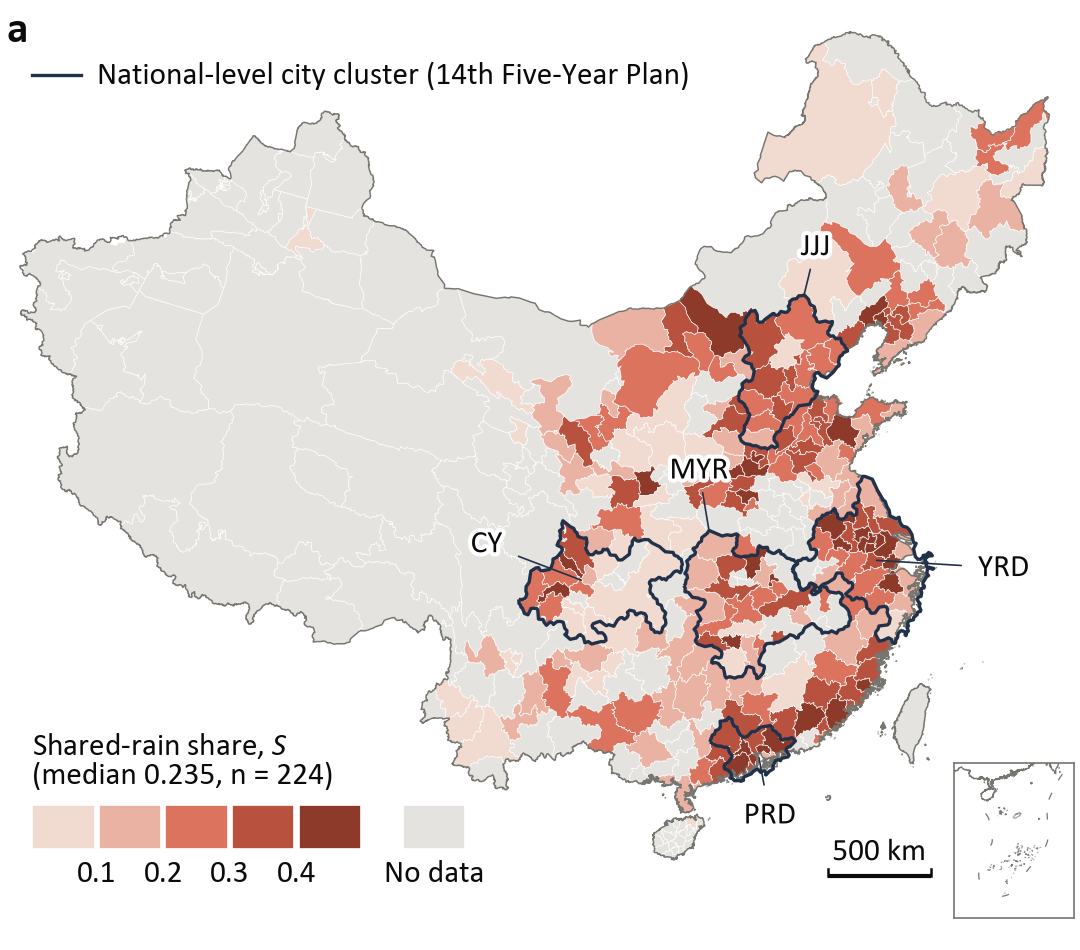

In [2]:
sdat = pd.read_excel(BOOK, sheet_name="Fig4a")
members = pd.read_excel(BOOK, sheet_name="Fig4a_clusters")

X0, Y0, PW, PH = 0.0, 3.18, 3.60, H - 3.18
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
cities, full, border, border_main = read_boundaries(3000)
outlines = cluster_outlines(full, members)
AX, AY, AW, AH = 0.0, H - 0.04 - 2.94, 3.58, 2.94
axa = ax_in(AX, AY, AW, AH)
letter(0.02, ROW1, "a")
cities.plot(ax=axa, facecolor=NODATA, edgecolor=EDGE, linewidth=0.15, zorder=1)
ma = cities.merge(sdat, on="city_name", how="inner")
ma.plot(ax=axa, color=[S_COLORS[k] for k in ma.S_class], edgecolor=EDGE, linewidth=0.15, zorder=2)
border_main.plot(ax=axa, color=INK3, linewidth=0.35, zorder=4)
axa.set_xlim(*MAIN_X)
axa.set_ylim(*MAIN_Y)
axa.set_aspect("equal")
axa.axis("off")
OFF = {"YRD": (6.6e5, -0.4e5), "PRD": (0.6e5, -3.2e5), "CY": (-5.0e5, 1.9e5)}
ABS = {"JJJ": (1.36e6, 5.00e6), "MYR": (0.79e6, 3.91e6)}
for k in BIG5:
    geom = outlines[k]
    gpd.GeoSeries([geom], crs=CRS).boundary.plot(ax=axa, color=NAVY, linewidth=0.8, zorder=6)
    p = geom.representative_point()
    if k in ABS:                                                # leader to the nearest point of the outline
        lab_ = Point(*ABS[k])
        p = geom.boundary.interpolate(geom.boundary.project(lab_))
        OFF[k] = (lab_.x - p.x, lab_.y - p.y)
    axa.annotate(k, xy=(p.x, p.y), xytext=(p.x + OFF[k][0], p.y + OFF[k][1]), fontsize=BASE, color=INK,
                 ha="center", va="center", path_effects=HALO,
                 arrowprops=dict(arrowstyle="-", lw=0.4, color=NAVY, shrinkA=0 if k in ABS else 2,
                                 shrinkB=0 if k in ABS else 2), zorder=9)
fig.canvas.draw()
pos = axa.get_position()
FW, FH = fig.get_size_inches()
aw, ah = pos.width * FW, pos.height * FH
rr = (MAIN_X[1] - MAIN_X[0]) / (MAIN_Y[1] - MAIN_Y[0])
mw, mh = (aw, aw / rr) if aw / ah < rr else (ah * rr, ah)
ins = fig.add_axes([(pos.x0 * FW + (aw + mw) / 2 - 0.40) / FW, (pos.y0 * FH + (ah - mh) / 2 - 0.12) / FH,
                    0.40 / FW, 0.585 / FH])
south_china_sea_inset(ins, border)
lx, ly, bw = 0.03, 0.05, 0.062
axa.text(lx, ly + 0.068, f"Shared-rain share, $S$\n(median {sdat.S.median():.3f}, n = {len(sdat)})",
         transform=axa.transAxes, fontsize=BASE, color=INK, ha="left", va="bottom", linespacing=1.05, zorder=10,
         bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
for i, col in enumerate(S_COLORS):
    axa.add_patch(Rectangle((lx + i * bw, ly), bw - 0.004, 0.05, transform=axa.transAxes, color=col, ec="white",
                            lw=0.4, zorder=9))
for i, t in enumerate(S_BREAKS[1:], start=1):
    axa.text(lx + i * bw - 0.002, ly - 0.012, f"{t:.1f}", transform=axa.transAxes, fontsize=BASE, color=INK,
             ha="center", va="top", zorder=9)
nx = lx + 5 * bw + 0.035
axa.add_patch(Rectangle((nx, ly), bw - 0.004, 0.05, transform=axa.transAxes, color=NODATA, ec="white", lw=0.4,
                        zorder=9))
axa.text(nx + (bw - 0.004) / 2, ly - 0.012, "No data", transform=axa.transAxes, fontsize=BASE, color=INK,
         ha="center", va="top", zorder=9)
ex, ey = 0.03, 0.928
axa.add_line(Line2D([ex, ex + 0.045], [ey, ey], transform=axa.transAxes, color=NAVY, lw=0.8, zorder=9))
axa.text(ex + 0.06, ey, "National-level city cluster (14th Five-Year Plan)", transform=axa.transAxes,
         fontsize=BASE, color=INK, ha="left", va="center", zorder=9)
sx0, sy0 = 1.42e6, 1.93e6                                       # 500 km scale bar, true along 108 E
axa.add_line(Line2D([sx0, sx0 + 5e5], [sy0, sy0], color=INK, lw=1.0, solid_capstyle="butt", zorder=9))
for xx in (sx0, sx0 + 5e5):
    axa.add_line(Line2D([xx, xx], [sy0, sy0 + 3.5e4], color=INK, lw=0.6, zorder=9))
axa.text(sx0 + 2.5e5, sy0 + 5.0e4, "500 km", fontsize=BASE, color=INK, ha="center", va="bottom", zorder=9,
         path_effects=HALO)
plt.show()

**Panel b**: mean S of each host's partners inside versus outside its own city cluster.

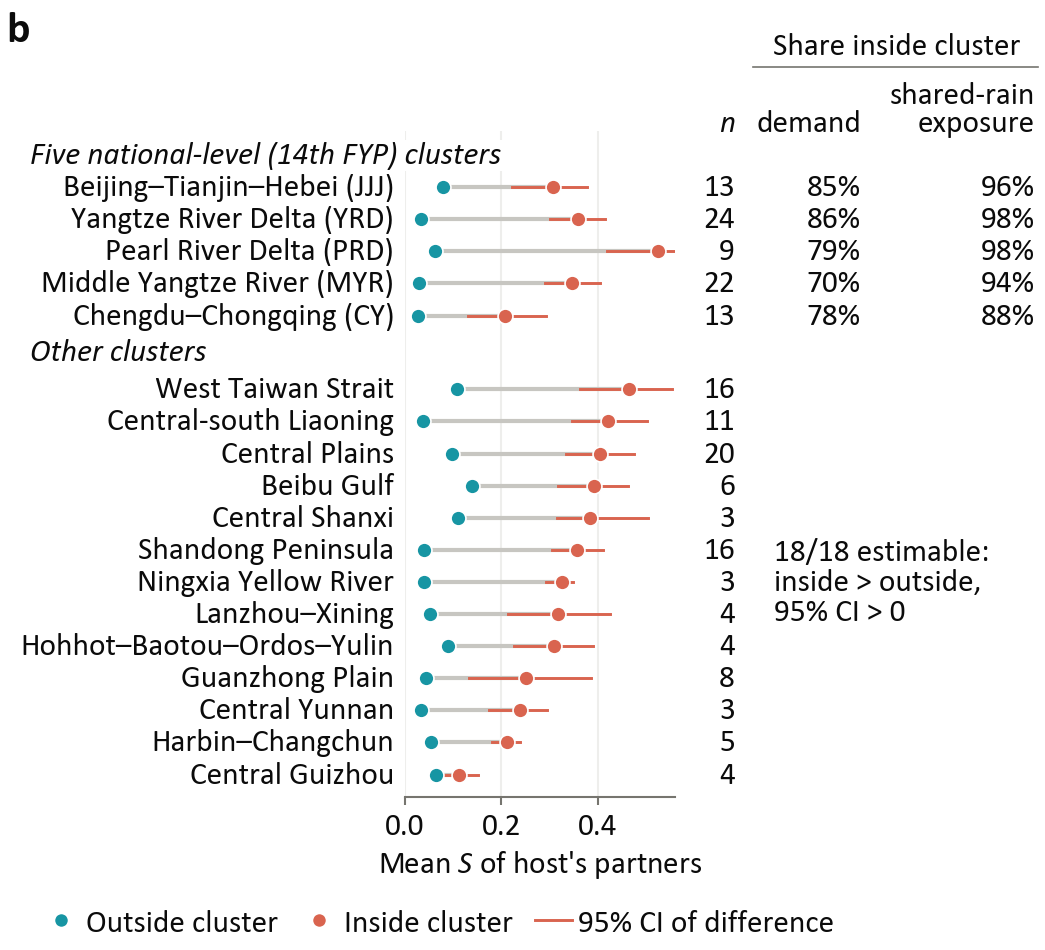

In [3]:
c = pd.read_excel(BOOK, sheet_name="Fig4b").sort_values("row_order")

X0, Y0, PW, PH = 3.60, 3.18, WIDTH - 3.60, H - 3.18
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
CX, CY0, CW, CH = 4.95, 3.69, 0.90, 2.22
BL = 3.70
axc = ax_in(CX, CY0, CW, CH)
letter(3.62, ROW1, "b")
clean(axc, "x")
fx = lambda xin_: (xin_ - CX) / CW                              # inches -> axes fraction
ys, yy, heads = [], 0.0, {}
heads["Five national-level (14th FYP) clusters"] = yy
yy -= 1.0
for r in c.itertuples():
    ys.append(yy)
    yy -= 1.0
    if r.cluster_code == BIG5[-1]:
        heads["Other clusters"] = yy - 0.15
        yy -= 1.3
c["y"] = ys
ytr = axc.get_yaxis_transform()
XN, XD, XE = 6.05, 6.47, 7.05
for r in c.itertuples():
    axc.plot([r.mean_S_outside, r.mean_S_inside], [r.y, r.y], color=GREY, lw=1.0, solid_capstyle="butt", zorder=2)
    axc.plot([r.mean_S_outside + r.difference_ci_low, r.mean_S_outside + r.difference_ci_high], [r.y, r.y], color=CORAL,
             lw=LW_CI, zorder=3)
    axc.scatter([r.mean_S_outside], [r.y], s=MS * 0.8, color=TEAL, edgecolor="white", lw=0.4, zorder=4)
    axc.scatter([r.mean_S_inside], [r.y], s=MS * 0.8, color=CORAL, edgecolor="white", lw=0.4, zorder=4)
    label = f"{r.cluster_name} ({r.cluster_code})" if r.national_level == 1 else r.cluster_name
    axc.text(-0.04, r.y, label, fontsize=BASE, color=INK, ha="right", va="center", transform=ytr)
    axc.text(fx(XN), r.y, f"{int(r.n_hosts)}", fontsize=BASE, color=INK, ha="right", va="center", transform=ytr)
    if r.national_level == 1:
        axc.text(fx(XD), r.y, f"{100 * r.demand_share_inside:.0f}%", fontsize=BASE, color=INK, ha="right",
                 va="center", transform=ytr)
        axc.text(fx(XE), r.y, f"{100 * r.exposure_share_inside:.0f}%", fontsize=BASE, color=INK, ha="right",
                 va="center", transform=ytr)
for h, yh in heads.items():
    axc.text(fx(BL), yh, h, fontsize=BASE, color=INK, ha="left", va="center", style="italic", transform=ytr,
             bbox=dict(facecolor="white", edgecolor="none", pad=0.4))
top = heads["Five national-level (14th FYP) clusters"]
ytop = CY0 + CH
T(XN, ytop - 0.02, "n", ha="right", va="bottom", style="italic")
T(XD, ytop - 0.02, "demand", ha="right", va="bottom")
T(XE, ytop - 0.02, "shared-rain\nexposure", ha="right", va="bottom", linespacing=1.0)
T((XD - 0.34 + XE) / 2, ytop + 0.235, "Share inside cluster", ha="center", va="bottom")
fig.add_artist(Line2D([(XD - 0.36 - X0) / PW, (XE + 0.01 - X0) / PW], [(ytop + 0.215 - Y0) / PH] * 2, color=INK3,
                      lw=0.4))
n_est = len(c)
n_pos = int(((c.difference > 0) & (c.difference_ci_low > 0)).sum())
g_other = c.loc[c.national_level == 0, "y"]
axc.text(fx(XN + 0.13), (g_other.max() + g_other.min()) / 2, f"{n_pos}/{n_est} estimable:\ninside > outside,\n95% CI > 0",
         fontsize=BASE, color=INK, ha="left", va="center", linespacing=1.1, transform=ytr)
axc.set_ylim(c.y.min() - 0.7, top + 0.75)
axc.set_yticks([])
axc.spines["left"].set_visible(False)
axc.set_xlim(0, 0.56)
axc.set_xticks([0, 0.2, 0.4])
axc.set_xlabel("Mean $S$ of host's partners")
hc = [Line2D([], [], marker="o", ls="", color=TEAL, mec="white", ms=4, label="Outside cluster"),
      Line2D([], [], marker="o", ls="", color=CORAL, mec="white", ms=4, label="Inside cluster"),
      Line2D([], [], color=CORAL, lw=LW_CI, label="95% CI of difference")]
axc.legend(handles=hc, loc="upper left", bbox_to_anchor=(fx(BL), -0.15), ncol=3, handletextpad=0.2,
           columnspacing=0.7, handlelength=1.2, borderaxespad=0, fontsize=BASE)
plt.show()

**Panel c**: top-minus-bottom tercile difference in median S for eight city attributes, raw and after removing location.

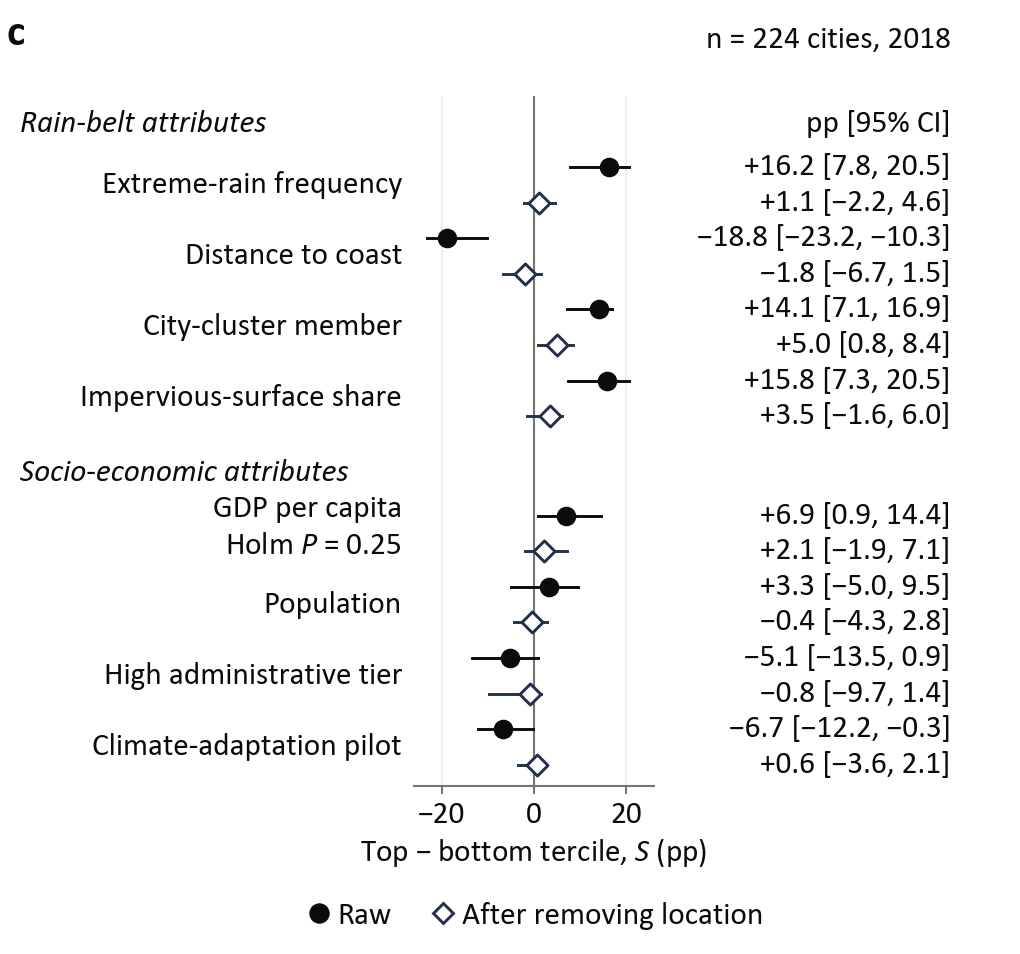

In [4]:
d = pd.read_excel(BOOK, sheet_name="Fig4c")

X0, Y0, PW, PH = 0.0, 0.0, 3.40, 3.18
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
DX, DY, DW, DH = 1.38, 0.56, 0.80, 2.30
CR = 3.17
axd = ax_in(DX, DY, DW, DH)
letter(0.02, ROW2, "c")
clean(axd, "x")
VCOL = (CR - DX) / DW
COLV = {"raw": INK, "after removing location": NAVY}
MKR = {"raw": "o", "after removing location": "D"}
OFFS = {"raw": 0.25, "after removing location": -0.25}
dtr = axd.get_yaxis_transform()
yy = 0.0
for g in d.attribute_group.unique():
    axd.text(-1.64, yy, g, fontsize=BASE, color=INK, ha="left", va="center", style="italic", transform=dtr)
    yy -= 0.85
    for v in d.loc[d.attribute_group == g, "variable"].unique():
        rows = d.loc[d.variable == v]
        for ver in ("raw", "after removing location"):
            q = rows.loc[rows.version == ver].iloc[0]
            yv, col = yy + OFFS[ver], COLV[ver]
            axd.plot([q.ci_low_pp, q.ci_high_pp], [yv, yv], color=col, lw=LW_CI, zorder=2)
            axd.scatter([q.difference_pp], [yv], s=MS if ver == "raw" else MS * 0.8, marker=MKR[ver],
                        facecolor=col if ver == "raw" else "white", edgecolor=col, lw=0.7, zorder=3)
            axd.text(VCOL, yv, ci_txt(q.difference_pp, q.ci_low_pp, q.ci_high_pp), fontsize=BASE, color=INK,
                     ha="right", va="center", transform=dtr)
        lab = rows.attribute.iloc[0]
        if v == "gdppc":                                        # attribute and its Holm P on two lines
            p_holm = rows.loc[rows.version == "raw", "p_holm"].iloc[0]
            axd.text(-0.05, yy + 0.34, lab, fontsize=BASE, color=INK, ha="right", va="center", transform=dtr)
            axd.text(-0.05, yy - 0.17, f"Holm {pfmt(p_holm)}", fontsize=BASE, color=INK, ha="right", va="center",
                     transform=dtr)
        else:
            axd.text(-0.05, yy, lab, fontsize=BASE, color=INK, ha="right", va="center", transform=dtr)
        yy -= 1.0
    yy -= 0.05
axd.text(VCOL, 0.0, "pp [95% CI]", fontsize=BASE, color=INK, ha="right", va="center", transform=dtr)
axd.axvline(0, color=INK3, lw=0.5, zorder=1)
axd.set_ylim(yy + 0.5, 0.4)
axd.set_yticks([])
axd.spines["left"].set_visible(False)
axd.set_xlim(-26, 26)
axd.set_xticks([-20, 0, 20])
axd.set_xlabel("Top − bottom tercile, $S$ (pp)")
hd = [Line2D([], [], marker="o", ls="", color=INK, mfc=INK, mew=0.7, ms=4.2, label="Raw"),
      Line2D([], [], marker="D", ls="", color=NAVY, mfc="white", mew=0.7, ms=3.4, label="After removing location")]
axd.legend(handles=hd, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, handletextpad=0.15,
           columnspacing=1.2, handlelength=0.9, borderaxespad=0, fontsize=BASE)
T(CR, ROW2 - 0.035, f"n = {int(d.n_cities.iloc[0])} cities, 2018", ha="right", va="top")
plt.show()

**Panel d**: cumulative spending deficit after the last day of extreme rain, in-person and remote sectors (upper) and their difference (lower).

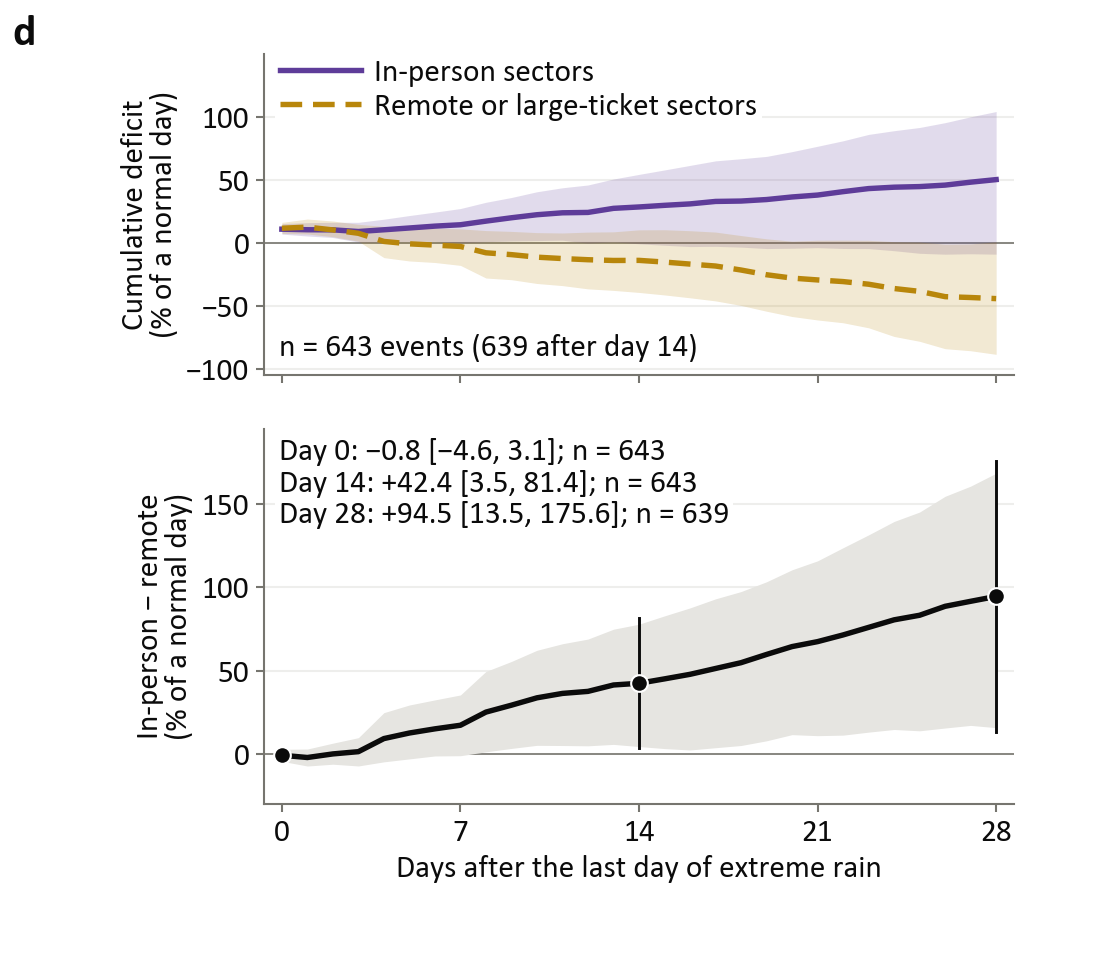

In [5]:
sec = pd.read_excel(BOOK, sheet_name="Fig4d")
S3 = {m: sec.loc[sec.margin == m].set_index("days_after_last_rain_day").sort_index()
      for m in ("in-person", "remote or large-ticket", "in-person minus remote")}

X0, Y0, PW, PH = 3.40, 0.0, WIDTH - 3.40, 3.18
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
EX, EW = 4.28, 2.50
axe = ax_in(EX, 1.93, EW, 1.07)
axf = ax_in(EX, 0.50, EW, 1.25)
letter(3.44, ROW2, "d")
hs = np.arange(29)
SEC = {"in-person": (PURPLE, "-", "In-person sectors"),
       "remote or large-ticket": (GOLD, (0, (4, 2)), "Remote or large-ticket sectors")}
for ax_ in (axe, axf):
    clean(ax_, "y")
    ax_.axhline(0, color=INK3, lw=0.4, zorder=1)
    ax_.set_xlim(-0.7, 28.7)
    ax_.set_xticks([0, 7, 14, 21, 28])
for m, (col, ls_, lab) in SEC.items():
    g = S3[m]
    axe.fill_between(hs, g.band_low, g.band_high, color=col, alpha=0.18, lw=0, zorder=2)
    axe.plot(hs, g.cumulative_deficit_pct_normal_day, color=col, lw=1.3, ls=ls_, zorder=3, label=lab)
axe.set_ylim(-105, 150)
axe.set_yticks([-100, -50, 0, 50, 100])
axe.set_yticklabels([nfmt(v, 0) for v in (-100, -50, 0, 50, 100)])
axe.tick_params(labelbottom=False)
axe.set_ylabel("Cumulative deficit\n(% of a normal day)", linespacing=1.05)
axe.legend(loc="upper left", bbox_to_anchor=(0.015, 1.0), handlelength=2.6, handletextpad=0.4, borderaxespad=0,
           labelspacing=0.2, fontsize=BASE, frameon=True, facecolor="white", edgecolor="none", framealpha=1,
           borderpad=0.15)
g = S3["in-person minus remote"]
n14, n28 = int(g.n_events.loc[14]), int(g.n_events.loc[28])
axe.text(0.02, 0.04, f"n = {n14} events ({n28} after day 14)", transform=axe.transAxes, fontsize=BASE, color=INK,
         ha="left", va="bottom")
axf.fill_between(hs, g.band_low, g.band_high, color=BAND, lw=0, zorder=2)
axf.plot(hs, g.cumulative_deficit_pct_normal_day, color=INK, lw=1.3, zorder=3)
for h in (0, 14, 28):
    axf.plot([h, h], [g.ci_low_twoway[h], g.ci_high_twoway[h]], color=INK, lw=LW_CI, zorder=4)
    axf.scatter([h], [g.cumulative_deficit_pct_normal_day[h]], s=MS, color=INK, edgecolor="white", lw=0.5, zorder=5)
axf.set_ylim(-30, 195)
axf.set_yticks([0, 50, 100, 150])
axf.set_ylabel("In-person − remote\n(% of a normal day)", linespacing=1.05)
axf.set_xlabel("Days after the last day of extreme rain")
head = [f"Day {h}: {ci_txt(g.cumulative_deficit_pct_normal_day[h], g.ci_low_twoway[h], g.ci_high_twoway[h])}; "
        f"n = {int(g.n_events[h])}" for h in (0, 14, 28)]
axf.text(0.02, 0.975, "\n".join(head), transform=axf.transAxes, fontsize=BASE, color=INK, ha="left", va="top",
         linespacing=1.15, bbox=dict(facecolor="white", edgecolor="none", pad=1.0), zorder=6)
plt.show()